# V10: move above 20th place

Outcome target: rank19 or better on the complete live Kaggle leaderboard.
Starting official loss0.83053, rank30/312; observed19th-place cutoff0.82915.

The deployed baseline combines original-order Gemma2-9B and swapped-order
ArmoRM/Llama3-8B predictions equally. The candidate adds reverse-order checks
where aligned experts disagree, under a fixed10%work/20%rows budget. Routed
rows receive the equal four-prediction average; other rows keep the base mean.
There are no fitted mixture weights or leaderboard parameter searches.

Both checkpoints were trained on original competition votes. Local losses,
class diagnostics and paired intervals below are **descriptive and training-
overlapping**, not independent validation or proof of a deployment gain.
The official submission and current rank are the outcome evidence.


In [1]:
from pathlib import Path
import json,sys
import numpy as np,pandas as pd,matplotlib.pyplot as plt
REPO=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'PROJECT_POLICY.md').exists())
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
PUB=REPO/'results/span_010';RUN=ROOT/'runs/span_010'
read=lambda p:json.loads(p.read_text())
Q=read(PUB/'H57_qualification.json') if (PUB/'H57_qualification.json').exists() else None
for role in ['order_pilot','order_packed']:
    for name in [role+'_source_verification.json','jobs/'+role+'/status.json']:
        path=PUB/name
        if path.exists():print(name,read(path))
print('Independent local quality evidence:',False)


order_pilot_source_verification.json {'passed': True, 'at': '2026-11-07T08:33:24.677976+00:00', 'kernel_version': 'arseniytrushin/llm-preference-span010-order-completion/1', 'notebook_sha256': 'c881bd98b950e1fbbaae20d29a4a417aaa843262cae1694ec215a6ec0de24f8e', 'cell_sources_identical': True, 'internet_enabled': False, 'remote_docker_image': 'gcr.io/kaggle-private-byod/python@sha256:e3f9bf91d1b7b36bf77554565d27c5733585fbe5e2b7f0832e068824e7accc3c', 'remote_dataset_sources': ['tascj0/lmsys-checkpoints-0-0805', 'tascj0/lmsys-checkpoints-3-0805', 'tascj0/lmsys-modules-0805', 'tascj0/lmsys-packages']}
jobs/order_pilot/status.json {'status': 'COMPLETE', 'kernel_version': 'arseniytrushin/llm-preference-span010-order-completion/1', 'observed_at': '2026-11-07T08:16:44.192599+00:00'}
order_packed_source_verification.json {'passed': True, 'at': '2026-11-07T09:21:43.166156+00:00', 'kernel_version': 'arseniytrushin/llm-preference-span010-packed-order-completion/1', 'notebook_sha256': 'b4ac54a1ce591

## Inference validity and runtime

The frozen uniform256 control replays the previous implementation. A separate
uniform512 cohort estimates runtime; longest64 is a stress cohort. Selected
reverse rows are timed through actual model inference. Projection includes20%
margin, all four measured cold starts/warmups, and600seconds reserve. Each hidden
run must remain below32400seconds. Failed controls/gates remain visible.


,role,hours,runtime_gate,controls
0,order_pilot,9.166346,False,True
1,order_packed,10.162927,False,False


,rows,max_abs_probability_difference,passed
m0,256,0.000214,False
m3,256,0.000612,False


,rows,selected_rows,route_replayed,mixture_replayed,max_abs_js_replay_difference,selected_work_fraction,mean_disagreement,selected_mean_disagreement,descriptive_loss_reduction,descriptive_paired_group95,independent,original_votes_seen_in_checkpoint_training
control,256,42,True,True,0.0,0.099494,0.013277,0.052847,0.001214,"[-0.000945, 0.003404]",False,True
uniform,512,83,True,True,0.0,0.099805,0.014044,0.056584,0.001233,"[-0.000199, 0.002713]",False,True
long,64,6,True,True,0.0,0.089096,0.007928,0.034364,-0.001731,"[-0.005612, 0.001171]",False,True
test,3,0,True,True,0.0,0.0,0.00214,None,NaN,NaN,NaN,NaN


,role,cohort,rows,seconds,tokens
0,m0,warmup,8,21.349264,6366
1,m0,control,256,173.467958,240851
2,m0,uniform,512,312.998725,477424
3,m0,long,64,196.714187,276229
4,m0,test,3,3.039762,2936
5,m3,warmup,8,16.717212,6227
6,m3,control,256,118.399422,233953
7,m3,uniform,512,227.079288,462769
8,m3,long,64,131.578080,276423
9,m3,test,3,2.166520,2787


Conservative hidden hours: 10.162926747716911
Runtime gate: False Both T4s verified: True


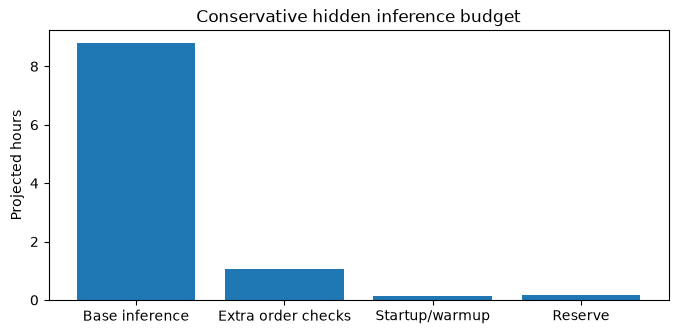

In [2]:
if Q is None:
    print('GPU audit pending; no measured quality/runtime result yet.')
else:
    history=[]
    for role in ['order_pilot','order_packed']:
        path=PUB/('H57_'+role+'_qualification.json')
        if path.exists():
            q=read(path);history.append(dict(role=role,hours=q['runtime_projection_seconds']/3600,
                runtime_gate=q['runtime_gate_passed'],controls=q['all_controls_passed']))
    display(pd.DataFrame(history))
    display(pd.DataFrame(Q['control_identity']).T)
    display(pd.DataFrame(Q['coverage']).T)
    rows=[]
    for role,s in Q['measured_roles'].items():
        for cohort,c in s['cohorts'].items():
            rows.append(dict(role=role,cohort=cohort,rows=c['rows'],seconds=c['seconds'],tokens=c['tokens']))
    display(pd.DataFrame(rows))
    print('Conservative hidden hours:',Q['runtime_projection_seconds']/3600)
    print('Runtime gate:',Q['runtime_gate_passed'],'Both T4s verified:',Q['both_t4_verified'])
    fig,ax=plt.subplots(figsize=(8,3.5))
    pieces=[Q['base_seconds_per_row']*25000*1.2,Q['reverse_seconds_per_all_row']*25000*1.2,Q['startup_seconds'],600]
    ax.bar(['Base inference','Extra order checks','Startup/warmup','Reserve'],np.array(pieces)/3600)
    ax.set(ylabel='Projected hours',title='Conservative hidden inference budget')
    plt.show()


## Descriptive error and order diagnostics

These are the same rows and unchanged human votes for every comparison.
Single-model full TTA and the full four-pass ensemble are diagnostics only;
the primary candidate/routing rule was frozen before this pilot. Confidence
intervals describe these observed, training-overlapping rows.


,cohort,model,rows,descriptive_log_loss,accuracy,independent
0,control,base,256,0.599422,0.773438,False
1,control,candidate,256,0.598208,0.773438,False
4,control,full_four,256,0.598794,0.781250,False
2,control,gemma_tta,256,0.654897,0.734375,False
3,control,llama_tta,256,0.562807,0.796875,False
10,long,base,64,0.896535,0.609375,False
11,long,candidate,64,0.898265,0.609375,False
14,long,full_four,64,0.901708,0.609375,False
12,long,gemma_tta,64,0.907045,0.625000,False
13,long,llama_tta,64,0.908790,0.546875,False


,cohort,model,target,log_loss
0,control,base,winner_model_a,0.532218
1,control,base,winner_model_b,0.531873
2,control,base,winner_tie,0.765123
3,control,candidate,winner_model_a,0.530511
4,control,candidate,winner_model_b,0.530645
5,control,candidate,winner_tie,0.764544
6,control,gemma_tta,winner_model_a,0.594298
7,control,gemma_tta,winner_model_b,0.588281
8,control,gemma_tta,winner_tie,0.811176
9,control,llama_tta,winner_model_a,0.488498


control descriptive reduction 0.0012143995736810936 paired group95% [-0.0009448659009201985, 0.0034035769005132162]
uniform descriptive reduction 0.0012330978204581873 paired group95% [-0.00019925540114395376, 0.0027129690446264765]
long descriptive reduction -0.0017307714191157767 paired group95% [-0.005612214511459256, 0.0011710844982875195]


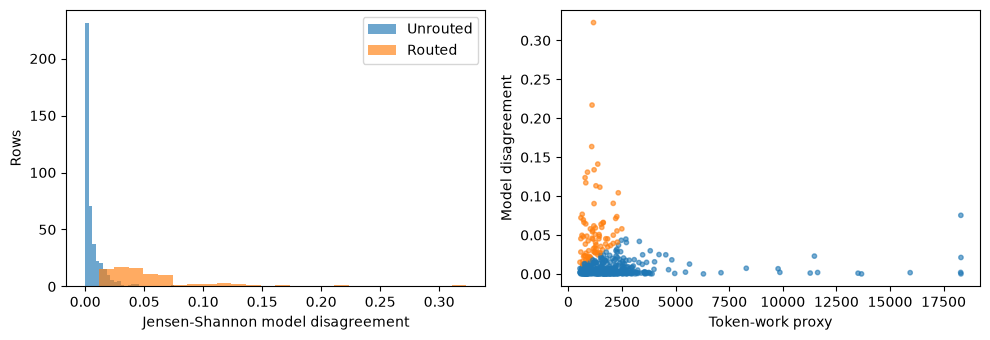

In [3]:
if Q is not None:
    metrics=pd.DataFrame(Q['descriptive_metrics'])
    display(metrics.drop(columns=['class_log_loss']).sort_values(['cohort','model']))
    class_rows=[]
    for row in Q['descriptive_metrics']:
        for target,value in row['class_log_loss'].items():
            class_rows.append(dict(cohort=row['cohort'],model=row['model'],target=target,log_loss=value))
    display(pd.DataFrame(class_rows))
    for name in ['control','uniform','long']:
        c=Q['coverage'][name]
        print(name,'descriptive reduction',c['descriptive_loss_reduction'],'paired group95%',c['descriptive_paired_group95'])
    out=RUN/'jobs'/Q.get('role','order_pilot')/'output/order_completion'
    d=np.load(out/'routing_uniform.npz');selected=d['selected_indices'];mask=np.zeros(len(d['ids']),dtype=bool);mask[selected]=True
    fig,axes=plt.subplots(1,2,figsize=(10,3.5))
    axes[0].hist(d['disagreement'][~mask],bins=25,alpha=.65,label='Unrouted')
    axes[0].hist(d['disagreement'][mask],bins=25,alpha=.65,label='Routed');axes[0].legend()
    axes[0].set(xlabel='Jensen-Shannon model disagreement',ylabel='Rows')
    axes[1].scatter(d['work'],d['disagreement'],s=10,c=np.where(mask,'C1','C0'),alpha=.6)
    axes[1].set(xlabel='Token-work proxy',ylabel='Model disagreement');plt.tight_layout();plt.show()


## Actual resources and official result

The public phase is capped at six elapsed T4x2 session-hours, including failures;
the initial pilot is capped at90minutes. Paid scaling stays off. Official receipt
wall time includes queue/obfuscation and is not measured GPU usage. A pending
result is displayed explicitly and does not complete the rank objective.


In [4]:
for role in ['order_pilot','order_packed']:
    state=PUB/'jobs'/role/'controller_state.json'
    if state.exists():print(role,read(state))
for name in ['official_receipt.json','official_result.json','official_leaderboard.json']:
    path=PUB/name;print(name,read(path) if path.exists() else 'Not submitted / pending')
print('Completion requires a fresh complete leaderboard observation with team17244411 at rank<=19.')


order_pilot {'stage': 'complete', 'at': '2026-11-07T08:17:04.398613+00:00', 'pid': 3356928, 'role': 'order_pilot', 'status': 'COMPLETE', 'kernel_version': 'arseniytrushin/llm-preference-span010-order-completion/1', 'charged_seconds': 2802.478, 'files': 50}
order_packed {'stage': 'complete', 'at': '2026-11-07T09:20:57.485287+00:00', 'pid': 3539313, 'role': 'order_packed', 'status': 'COMPLETE', 'kernel_version': 'arseniytrushin/llm-preference-span010-packed-order-completion/1', 'charged_seconds': 3033.054, 'files': 50}
official_receipt.json Not submitted / pending
official_result.json Not submitted / pending
official_leaderboard.json Not submitted / pending
Completion requires a fresh complete leaderboard observation with team17244411 at rank<=19.
